In [5]:
import duckdb
import pandas as pd
import plotly.express as px

con = duckdb.connect("france.duckdb", read_only=True)
con.execute("LOAD spatial")

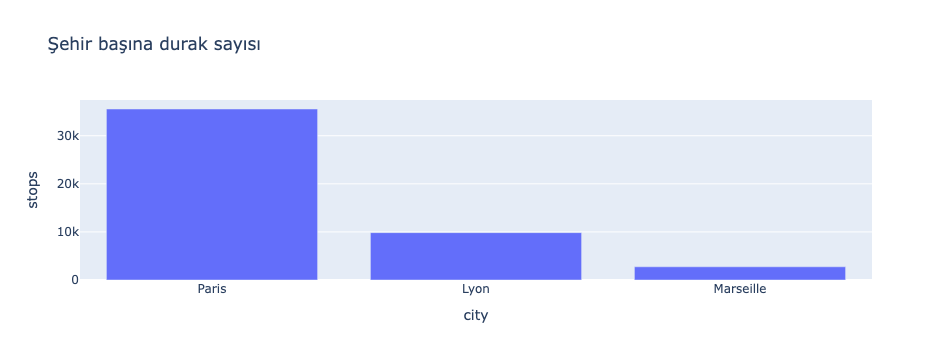

In [2]:
df = con.sql("""
    SELECT upper(city[1]) || city[2:] AS city, COUNT(*) AS stops
    FROM gtfs_stops
    WHERE COALESCE(NULLIF(location_type, ''), '0') = '0'
    GROUP BY 1 ORDER BY 2 DESC
""").df()
px.bar(df, x="city", y="stops", title="Şehir başına durak sayısı")

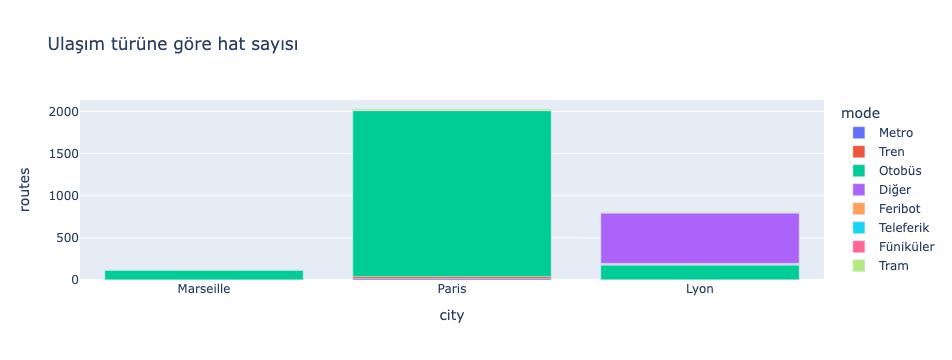

In [4]:
types = {"0": "Tram", "1": "Metro", "2": "Tren", "3": "Otobüs", "4": "Feribot", "6": "Teleferik", "7": "Füniküler"}
df = con.sql("SELECT upper(city[1]) || city[2:] AS city, route_type, COUNT(*) AS routes FROM gtfs_routes GROUP BY 1, 2").df()
df["mode"] = df["route_type"].map(types).fillna("Diğer")
px.bar(df, x="city", y="routes", color="mode", title="Ulaşım türüne göre hat sayısı")

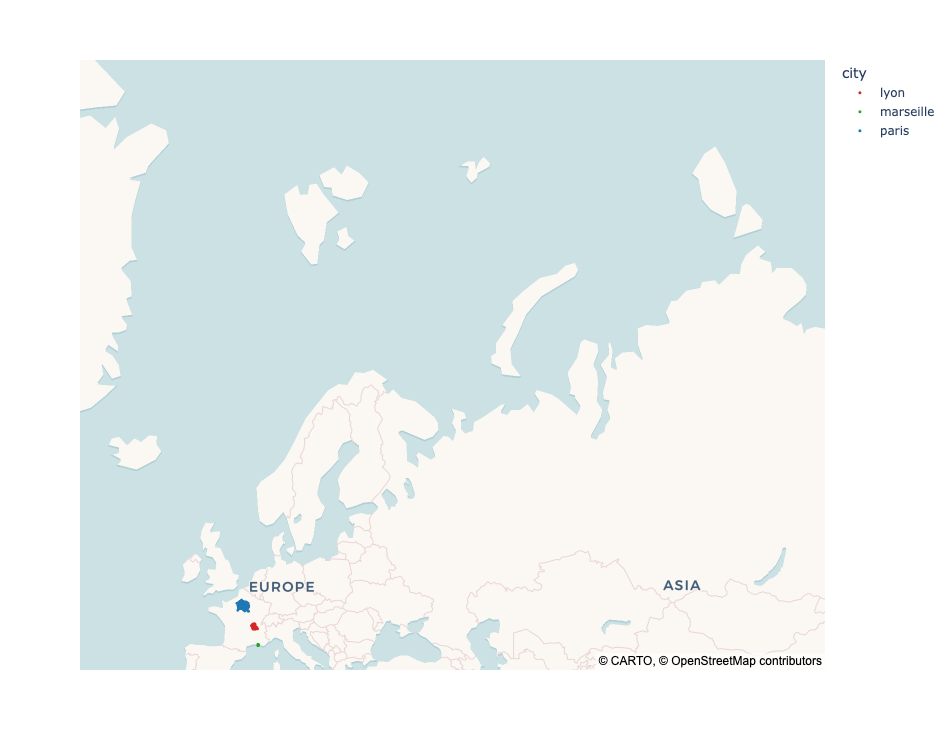

In [15]:
fig = px.scatter_map(
    df, lat="lat", lon="lon", color="city", hover_name="stop_name",
    color_discrete_map={"paris": "#1f77b4", "lyon": "#d62728", "marseille": "#2ca02c"},
    zoom=5, center={"lat": 46.5, "lon": 3.5}, height=750, map_style="carto-voyager",
)
fig.update_traces(marker=dict(size=3))
fig